
# Homework 3 — Classical NLP baseline

## 1. Experimental setup

In this notebook, I develop and evaluate classical machine learning baselines for multilingual AI-generated text detection.

I compare word-level and character-level TF-IDF representations with linear classification algorithms, including Logistic Regression and Linear Support Vector Machines.

I use the group-aware cross-validation folds created during exploratory data analysis to ensure consistent comparisons and reduce leakage from known related documents.

My primary evaluation metric is macro-averaged F1, with additional per-class metrics and confusion matrices to investigate the classification of `human`, `ai`, and `fusion` texts.

After selecting the strongest baseline, I will retrain it on the complete labeled training dataset and generate a Kaggle submission.

In [1]:
import os
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    f1_score,
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

warnings.filterwarnings("ignore", category=FutureWarning)

CLASS_ORDER = ["human", "ai", "fusion"]

CLASS_COLORS = {
    "human": "#6C3CC8",
    "ai": "#E96BA8",
    "fusion": "#A991E8"
}

sns.set_theme(
    style="whitegrid",
    palette=list(CLASS_COLORS.values()),
    rc={
        "figure.figsize": (10, 5),
        "figure.dpi": 120,
        "axes.titlesize": 15,
        "axes.titleweight": "bold",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "grid.alpha": 0.18
    }
)

pd.set_option("display.max_columns", None)

print("Environment configured successfully.")

Environment configured successfully.



## 2. Data loading and validation setup

I load the original competition datasets and the previously saved group-aware fold assignments.

I use fold 0 as the fixed validation set for initial model development. The remaining four folds form the training set.

This approach ensures that all baseline configurations are evaluated on the same documents. I keep the validation set separate when fitting TF-IDF vectorizers and classification models to avoid data leakage.

In [2]:
%pip -q install -U kaggle

import zipfile
import subprocess

from google.colab import userdata, drive

os.environ["KAGGLE_API_TOKEN"] = (
    userdata.get("kaggle_token").strip()
)

COMPETITION = "ai-generated-text-detection-hw3-ucu-ai-2026"

DATA_DIR = Path("/content/hw3_data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

required_files = [
    "train.csv",
    "test.csv",
    "sample_submission.csv"
]

if not all((DATA_DIR / name).exists() for name in required_files):
    subprocess.run(
        [
            "kaggle", "competitions", "download",
            "-c", COMPETITION,
            "-p", str(DATA_DIR)
        ],
        check=True
    )

    for archive_path in DATA_DIR.glob("*.zip"):
        with zipfile.ZipFile(archive_path) as archive:
            archive.extractall(DATA_DIR)

train_df = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")
sample_submission = pd.read_csv(
    DATA_DIR / "sample_submission.csv"
)

print("Train:", train_df.shape)
print("Test:", test_df.shape)
print("Submission:", sample_submission.shape)

Train: (272352, 5)
Test: (25000, 4)
Submission: (25000, 2)


In [3]:
drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/UCU_AI_HW3")

fold_path = PROJECT_DIR / "cv_folds_v1.csv"

fold_df = pd.read_csv(
    fold_path,
    dtype={"id": str}
)

assert fold_df["id"].is_unique
assert train_df["id"].is_unique

train_df = train_df.merge(
    fold_df[["id", "group_id", "cv_fold"]],
    on="id",
    how="left",
    validate="one_to_one"
)

assert train_df["cv_fold"].notna().all()
assert train_df["cv_fold"].between(0, 4).all()
assert train_df.groupby("group_id")["cv_fold"].nunique().max() == 1

print("Fold assignments loaded successfully.")

display(
    train_df["cv_fold"]
    .value_counts()
    .sort_index()
)

Mounted at /content/drive
Fold assignments loaded successfully.


,count
cv_fold,
0,55031
1,54801
2,54569
3,53926
4,54025



## 3. Fixed validation split

I reserve fold 0 for validation and use folds 1–4 for training.

All initial baseline experiments use this fixed split, allowing direct comparison of model performance. I use only the text column as input, without explicit language or domain metadata.

The validation set is used exclusively for evaluation and model selection. TF-IDF vocabulary and IDF statistics are fitted only on the training portion.

In [4]:
VALIDATION_FOLD = 0

train_mask = train_df["cv_fold"] != VALIDATION_FOLD
val_mask = train_df["cv_fold"] == VALIDATION_FOLD

X_train = train_df.loc[train_mask, "text"]
y_train = train_df.loc[train_mask, "label"]

X_val = train_df.loc[val_mask, "text"]
y_val = train_df.loc[val_mask, "label"]

assert set(
    train_df.loc[train_mask, "group_id"]
).isdisjoint(
    set(train_df.loc[val_mask, "group_id"])
)

print(f"Training examples: {len(X_train):,}")
print(f"Validation examples: {len(X_val):,}")

print("\nTraining class distribution:")
display(y_train.value_counts(normalize=True).round(4))

print("\nValidation class distribution:")
display(y_val.value_counts(normalize=True).round(4))

Training examples: 217,321
Validation examples: 55,031

Training class distribution:


,proportion
label,
ai,0.4474
fusion,0.3078
human,0.2448



Validation class distribution:


,proportion
label,
ai,0.4492
fusion,0.3050
human,0.2458


In [5]:
experiment_results = []

def evaluate_model(model, X_val, y_val, model_name):
    predictions = model.predict(X_val)

    macro_f1 = f1_score(
        y_val,
        predictions,
        labels=CLASS_ORDER,
        average="macro"
    )

    accuracy = accuracy_score(y_val, predictions)

    print(f"\nModel: {model_name}")
    print(f"Macro-F1: {macro_f1:.5f}")
    print(f"Accuracy: {accuracy:.5f}")

    print("\nClassification report:")
    print(
        classification_report(
            y_val,
            predictions,
            labels=CLASS_ORDER,
            digits=4,
            zero_division=0
        )
    )

    experiment_results.append({
        "Model": model_name,
        "Macro-F1": macro_f1,
        "Accuracy": accuracy
    })

    cm = confusion_matrix(
        y_val,
        predictions,
        labels=CLASS_ORDER,
        normalize="true"
    )

    fig, ax = plt.subplots(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt=".2%",
        cmap=sns.light_palette("#A991E8", as_cmap=True),
        xticklabels=CLASS_ORDER,
        yticklabels=CLASS_ORDER,
        ax=ax
    )

    ax.set(
        title=f"Confusion matrix — {model_name}",
        xlabel="Predicted class",
        ylabel="True class"
    )

    plt.tight_layout()
    plt.show()

    return predictions


## 4. Word-level TF-IDF baseline

I start with a word-level TF-IDF representation using unigrams and bigrams, followed by multinomial Logistic Regression.

TF-IDF captures the relative importance of words and short phrases, while Logistic Regression provides a simple and interpretable classification baseline.

I retain punctuation and the original text structure in the source data, but the default word tokenizer focuses on word-level patterns. Character-level representations will be evaluated separately.

I initially train the classifier without class weighting to establish a fixed reference for subsequent experiments.

In [6]:
import time

baseline_model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            analyzer="word",
            ngram_range=(1, 2),
            min_df=3,
            max_df=0.98,
            max_features=150_000,
            sublinear_tf=True,
            strip_accents=None,
            lowercase=True,
            dtype=np.float32
        )
    ),
    (
        "classifier",
        LogisticRegression(
            C=2.0,
            max_iter=300,
            solver="lbfgs",
            random_state=SEED
        )
    )
])

start_time = time.perf_counter()

baseline_model.fit(X_train, y_train)

training_time = time.perf_counter() - start_time

print("Training completed.")
print(f"Training time: {training_time:.1f} seconds")
print(
    "Vocabulary size:",
    len(baseline_model.named_steps["tfidf"].vocabulary_)
)

Training completed.
Training time: 637.1 seconds
Vocabulary size: 150000



Model: Word TF-IDF (1,2) + Logistic Regression
Macro-F1: 0.87852
Accuracy: 0.89777

Classification report:
              precision    recall  f1-score   support

       human     0.7774    0.8681    0.8203     13529
          ai     0.9824    0.9911    0.9867     24718
      fusion     0.8782    0.7842    0.8286     16784

    accuracy                         0.8978     55031
   macro avg     0.8794    0.8811    0.8785     55031
weighted avg     0.9002    0.8978    0.8976     55031



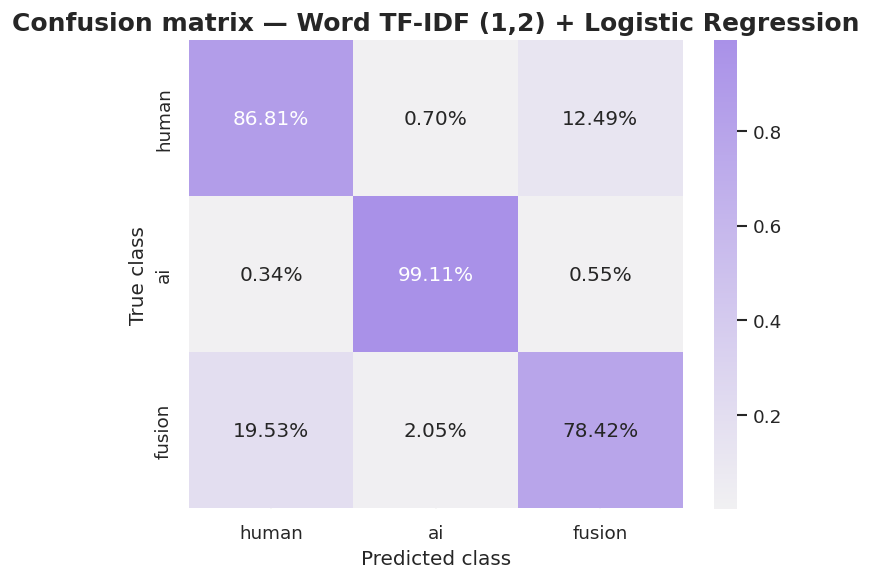

In [7]:
baseline_predictions = evaluate_model(
    model=baseline_model,
    X_val=X_val,
    y_val=y_val,
    model_name="Word TF-IDF (1,2) + Logistic Regression"
)

In [8]:
results_df = pd.DataFrame(experiment_results)

display(
    results_df.sort_values(
        "Macro-F1",
        ascending=False
    ).round(5)
)

baseline_per_class = classification_report(
    y_val,
    baseline_predictions,
    labels=CLASS_ORDER,
    output_dict=True,
    zero_division=0
)

per_class_df = pd.DataFrame(
    baseline_per_class
).T.loc[
    CLASS_ORDER,
    ["precision", "recall", "f1-score", "support"]
]

display(per_class_df.round(4))

,Model,Macro-F1,Accuracy
0,"Word TF-IDF (1,2) + Logistic Regression",0.87852,0.89777


,precision,recall,f1-score,support
human,0.7774,0.8681,0.8203,13529.0
ai,0.9824,0.9911,0.9867,24718.0
fusion,0.8782,0.7842,0.8286,16784.0



### Baseline error analysis

I analyze the classification errors of the initial word-level TF-IDF baseline, focusing on confusion between `human` and `fusion`.

I examine the confusion matrix and model performance across document lengths to identify which types of texts are most difficult to classify. These findings will guide the next baseline experiments.

In [9]:
cm = confusion_matrix(
    y_val,
    baseline_predictions,
    labels=CLASS_ORDER
)

cm_df = pd.DataFrame(
    cm,
    index=CLASS_ORDER,
    columns=CLASS_ORDER
)

print("Confusion matrix (counts):")
display(cm_df)

error_df = train_df.loc[
    val_mask, ["id", "label", "lang", "domain", "text"]
].copy()

error_df["prediction"] = baseline_predictions
error_df["word_count"] = error_df["text"].str.split().str.len()

error_df["length_group"] = pd.cut(
    error_df["word_count"],
    bins=[0, 256, 512, 1024, float("inf")],
    labels=["≤256", "257–512", "513–1024", ">1024"]
)

length_results = []

for group, subset in error_df.groupby(
    "length_group", observed=True
):
    length_results.append({
        "Length group": group,
        "Samples": len(subset),
        "Macro-F1": f1_score(
            subset["label"],
            subset["prediction"],
            labels=CLASS_ORDER,
            average="macro",
            zero_division=0
        ),
        "Fusion recall": (
            (
                (subset["label"] == "fusion") &
                (subset["prediction"] == "fusion")
            ).sum()
            / max((subset["label"] == "fusion").sum(), 1)
        )
    })

length_results_df = pd.DataFrame(length_results)

display(length_results_df.round(4))

Confusion matrix (counts):


,human,ai,fusion
human,11744,95,1690
ai,84,24499,135
fusion,3278,344,13162


,Length group,Samples,Macro-F1,Fusion recall
0,≤256,12587,0.8063,0.6943
1,257–512,18432,0.8912,0.8110
2,513–1024,19138,0.9077,0.8143
3,>1024,4874,0.9047,0.8119



### Baseline error analysis findings

The initial word-level TF-IDF baseline achieves a validation macro-F1 of 0.87852. The main classification challenge is distinguishing `human` from `fusion`: 3,278 fusion texts are predicted as human, while 1,690 human texts are predicted as fusion.

Performance also varies substantially with document length. Texts containing at most 256 words have a macro-F1 of 0.8063 and fusion recall of 0.6943, compared with macro-F1 scores above 0.89 for longer documents.

These findings motivate experiments with character-level features, alternative linear classifiers, and class-specific decision adjustments. I will also investigate whether the performance gap for short texts persists within individual languages and domains.



## 5. Character-level TF-IDF with LinearSVC

I investigate whether character-level TF-IDF features improve classification compared with the word-level baseline.

Character n-grams can capture local spelling patterns, punctuation, word fragments, and stylistic regularities that may be missed by word-level features.

I use a Linear Support Vector Classifier and evaluate it on the same fixed validation split. I focus particularly on macro-F1 and the confusion between human and fusion texts.


In [10]:
# import time

# char_model = Pipeline([
#     (
#         "tfidf",
#         TfidfVectorizer(
#             analyzer="char",
#             ngram_range=(3, 5),
#             min_df=5,
#             max_features=200_000,
#             sublinear_tf=True,
#             lowercase=True,
#             dtype=np.float32
#         )
#     ),
#     (
#         "classifier",
#         LinearSVC(
#             C=1.0,
#             class_weight=None,
#             max_iter=2000,
#             random_state=SEED
#         )
#     )
# ])

# start_time = time.perf_counter()

# char_model.fit(X_train, y_train)

# char_training_time = time.perf_counter() - start_time

# print("Character-level model trained successfully.")
# print(f"Training time: {char_training_time:.1f} seconds")
# print(
#     "Vocabulary size:",
#     len(char_model.named_steps["tfidf"].vocabulary_)
# )


### Memory-efficient character-level baseline

The initial character-level TF-IDF configuration exceeded the available RAM during vectorization of the full training dataset.

To address this limitation, I replace vocabulary-based TF-IDF with a hashing-based representation and incremental linear classification.

Hashing avoids storing an explicit character n-gram vocabulary, while mini-batch processing reduces peak memory consumption. I use an SGD-based linear SVM classifier and compare its validation macro-F1 with the original word-level baseline.


In [11]:
import gc
import time
import numpy as np

from sklearn.feature_extraction.text import HashingVectorizer
from sklearn.linear_model import SGDClassifier

hash_vectorizer = HashingVectorizer(
    analyzer="char",
    ngram_range=(3, 5),
    n_features=2**18,
    alternate_sign=False,
    norm="l2",
    lowercase=True,
    dtype=np.float32
)

char_classifier = SGDClassifier(
    loss="hinge",
    alpha=1e-5,
    random_state=SEED,
    average=True
)

BATCH_SIZE = 256
EPOCHS = 3

print("Memory-efficient character baseline configured.")

Memory-efficient character baseline configured.


In [12]:
start_time = time.perf_counter()

X_train_list = X_train.tolist()
y_train_array = y_train.to_numpy()

classes = np.array(CLASS_ORDER)
rng = np.random.default_rng(SEED)

for epoch in range(EPOCHS):
    indices = rng.permutation(len(X_train_list))

    for start in range(0, len(indices), BATCH_SIZE):
        batch_idx = indices[start:start + BATCH_SIZE]

        batch_texts = [
            X_train_list[i] for i in batch_idx
        ]

        X_batch = hash_vectorizer.transform(batch_texts)

        char_classifier.partial_fit(
            X_batch,
            y_train_array[batch_idx],
            classes=classes
        )

        del X_batch

    gc.collect()
    print(f"Epoch {epoch + 1}/{EPOCHS} completed.")

training_time = time.perf_counter() - start_time

print(f"Training time: {training_time:.1f} seconds")

Epoch 1/3 completed.
Epoch 2/3 completed.
Epoch 3/3 completed.
Training time: 3770.5 seconds


Character baseline macro-F1: 0.83332
Word baseline macro-F1: 0.87852
Difference: -0.04520
              precision    recall  f1-score   support

       human     0.7230    0.8190    0.7680     13529
          ai     0.9581    0.9871    0.9724     24718
      fusion     0.8273    0.7020    0.7595     16784

    accuracy                         0.8588     55031
   macro avg     0.8362    0.8360    0.8333     55031
weighted avg     0.8604    0.8588    0.8572     55031



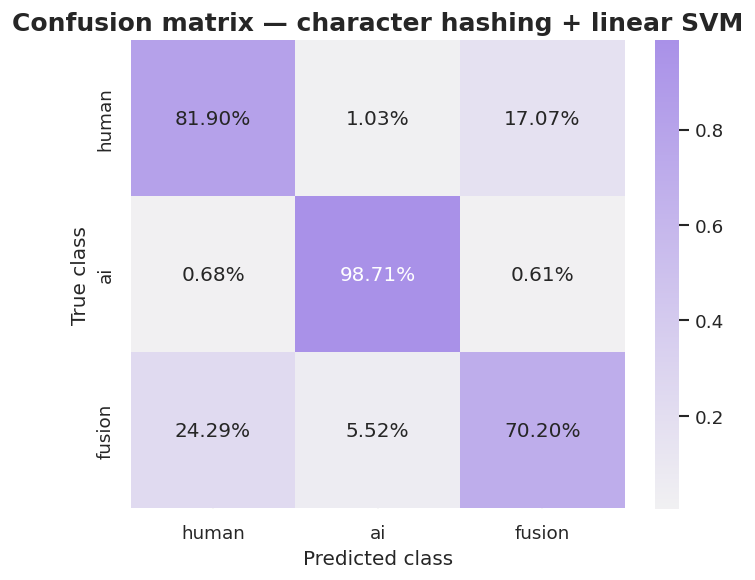

In [13]:
char_predictions = []

for start in range(0, len(X_val), BATCH_SIZE):
    batch_texts = X_val.iloc[start:start + BATCH_SIZE].tolist()

    X_batch = hash_vectorizer.transform(batch_texts)

    predictions = char_classifier.predict(X_batch)
    char_predictions.extend(predictions)

    del X_batch

char_predictions = np.asarray(char_predictions)

char_f1 = f1_score(
    y_val,
    char_predictions,
    labels=CLASS_ORDER,
    average="macro"
)

print(f"Character baseline macro-F1: {char_f1:.5f}")
print(f"Word baseline macro-F1: 0.87852")
print(f"Difference: {char_f1 - 0.87852:+.5f}")

print(
    classification_report(
        y_val,
        char_predictions,
        labels=CLASS_ORDER,
        digits=4,
        zero_division=0
    )
)

cm = confusion_matrix(
    y_val,
    char_predictions,
    labels=CLASS_ORDER,
    normalize="true"
)

fig, ax = plt.subplots(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt=".2%",
    cmap=sns.light_palette("#A991E8", as_cmap=True),
    xticklabels=CLASS_ORDER,
    yticklabels=CLASS_ORDER,
    ax=ax
)

ax.set(
    title="Confusion matrix — character hashing + linear SVM",
    xlabel="Predicted class",
    ylabel="True class"
)

plt.tight_layout()
plt.show()


### Character hashing experiment findings

The memory-efficient character hashing classifier achieved a validation macro-F1 of 0.83332, compared with 0.87852 for the word-level TF-IDF baseline.

The character-based model performed worse across all three classes, with fusion F1 decreasing from 0.8286 to 0.7595. Training also required substantially more time (3,536.6 seconds versus 638.1 seconds).

These results do not establish that character n-grams are inherently inferior, since the experiments differ in both feature representation and optimization algorithm. Nevertheless, this configuration did not improve performance and was considerably more computationally expensive.

I therefore retain the word-level TF-IDF model as my reference baseline.



## 6. First Kaggle submission

I select the word-level TF-IDF and Logistic Regression configuration as my initial submission model based on its superior validation macro-F1.

After completing model selection, I retrain the selected pipeline on the full labeled training dataset and generate predictions for the 25,000 competition test documents.

I preserve the official sample submission order and validate the output format before submission.


In [14]:
import time
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

final_baseline = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            analyzer="word",
            ngram_range=(1, 2),
            min_df=3,
            max_df=0.98,
            max_features=150_000,
            sublinear_tf=True,
            strip_accents=None,
            lowercase=True,
            dtype=np.float32
        )
    ),
    (
        "classifier",
        LogisticRegression(
            C=2.0,
            max_iter=300,
            solver="lbfgs",
            random_state=SEED
        )
    )
])

start_time = time.perf_counter()

final_baseline.fit(
    train_df["text"],
    train_df["label"]
)

training_time = time.perf_counter() - start_time

print("Final baseline training completed.")
print(f"Training time: {training_time / 60:.2f} minutes")
print(
    "Vocabulary size:",
    len(final_baseline.named_steps["tfidf"].vocabulary_)
)

Final baseline training completed.
Training time: 11.42 minutes
Vocabulary size: 150000


In [15]:
test_predictions = final_baseline.predict(test_df["text"])

prediction_df = pd.DataFrame({
    "id": test_df["id"],
    "label": test_predictions
})

submission = (
    sample_submission[["id"]]
    .merge(prediction_df, on="id", how="left", validate="one_to_one")
)

assert len(submission) == 25000
assert submission["id"].equals(sample_submission["id"])
assert submission["id"].is_unique
assert submission["label"].isin(CLASS_ORDER).all()
assert submission.columns.tolist() == ["id", "label"]

submission_path = PROJECT_DIR / "submission_word_tfidf_lr_v1.csv"
submission.to_csv(submission_path, index=False)

print("Submission saved:", submission_path)
print("\nPredicted class distribution:")
display(submission["label"].value_counts())
display(submission.head())

Submission saved: /content/drive/MyDrive/UCU_AI_HW3/submission_word_tfidf_lr_v1.csv

Predicted class distribution:


,count
label,
ai,12999
human,6820
fusion,5181


,id,label
0,8ff2d1,ai
1,a261cf,human
2,ad5614,fusion
3,3a23ac,ai
4,28b4e5,ai


In [16]:
import subprocess

result = subprocess.run(
    [
        "kaggle", "competitions", "submit",
        "-c", COMPETITION,
        "-f", str(submission_path),
        "-m", "Word TF-IDF Logistic Regression baseline v1"
    ],
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print(result.stdout)
print(result.stderr)

Return code: 0
Submission ref: 58659829
2 submissions remaining today.
Successfully submitted to AI-Generated Text Detection | HW3 | UCU AI 2026

  0%|          | 0.00/284k [00:00<?, ?B/s]
100%|██████████| 284k/284k [00:02<00:00, 119kB/s]




## 5. Logistic regression parameter search

I perform a small, controlled hyperparameter search for the strongest word-level TF-IDF baseline.

I retain the same training and validation folds to ensure a fair comparison with the original model. I reuse the TF-IDF representation fitted exclusively on the training data and vary the Logistic Regression regularization strength and class weighting.

The primary selection metric is validation macro-F1, which assigns equal importance to the `human`, `ai`, and `fusion` classes. I also monitor per-class F1, particularly for `fusion`, to understand the effect of each configuration.

I compare all configurations against the original baseline with `C=2.0` and no class weighting. This is a small exploratory parameter search rather than an exhaustive optimization procedure.


In [17]:
import gc
import time
import numpy as np
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from IPython.display import display

word_vectorizer = baseline_model.named_steps["tfidf"]

assert hasattr(word_vectorizer, "vocabulary_")

X_train_tfidf = word_vectorizer.transform(X_train)
X_val_tfidf = word_vectorizer.transform(X_val)

print("Training matrix:", X_train_tfidf.shape)
print("Validation matrix:", X_val_tfidf.shape)
print("Training non-zero features:", X_train_tfidf.nnz)
print("Validation non-zero features:", X_val_tfidf.nnz)

assert X_train_tfidf.shape[0] == 217_321
assert X_val_tfidf.shape[0] == 55_031
assert X_train_tfidf.shape[1] == X_val_tfidf.shape[1]

print("\nTF-IDF matrices prepared successfully.")

Training matrix: (217321, 150000)
Validation matrix: (55031, 150000)
Training non-zero features: 105842808
Validation non-zero features: 26868118

TF-IDF matrices prepared successfully.


In [18]:
search_configs = [
    {"C": 0.5, "class_weight": None},
    {"C": 1.0, "class_weight": None},
    {"C": 4.0, "class_weight": None},
    {"C": 2.0, "class_weight": "balanced"},
]

search_results = [{
    "C": 2.0,
    "class_weight": "none",
    "macro_f1": f1_score(
        y_val,
        baseline_predictions,
        labels=CLASS_ORDER,
        average="macro"
    ),
    "fusion_f1": f1_score(
        y_val,
        baseline_predictions,
        labels=CLASS_ORDER,
        average=None
    )[CLASS_ORDER.index("fusion")],
    "training_seconds": training_time,
    "reference": True
}]

for config in search_configs:

    start_time = time.perf_counter()

    classifier = LogisticRegression(
        C=config["C"],
        class_weight=config["class_weight"],
        solver="lbfgs",
        max_iter=300,
        random_state=SEED
    )

    classifier.fit(X_train_tfidf, y_train)

    predictions = classifier.predict(X_val_tfidf)

    elapsed = time.perf_counter() - start_time

    macro_f1 = f1_score(
        y_val,
        predictions,
        labels=CLASS_ORDER,
        average="macro",
        zero_division=0
    )

    per_class_f1 = f1_score(
        y_val,
        predictions,
        labels=CLASS_ORDER,
        average=None,
        zero_division=0
    )

    search_results.append({
        "C": config["C"],
        "class_weight": (
            config["class_weight"]
            if config["class_weight"] is not None
            else "none"
        ),
        "macro_f1": macro_f1,
        "fusion_f1": per_class_f1[
            CLASS_ORDER.index("fusion")
        ],
        "training_seconds": elapsed,
        "reference": False
    })

    print(
        f"C={config['C']}, "
        f"class_weight={config['class_weight']}: "
        f"macro-F1={macro_f1:.5f}, "
        f"fusion-F1={per_class_f1[2]:.5f}"
    )

    del classifier, predictions
    gc.collect()

search_df = pd.DataFrame(search_results)

search_df = search_df.sort_values(
    "macro_f1",
    ascending=False
).reset_index(drop=True)

print("\nParameter search results:")
display(search_df.round(5))

search_path = PROJECT_DIR / "baseline_parameter_search_v1.csv"
search_df.to_csv(search_path, index=False)

print("\nResults saved:", search_path)

C=0.5, class_weight=None: macro-F1=0.87237, fusion-F1=0.81722
C=1.0, class_weight=None: macro-F1=0.87527, fusion-F1=0.82355
C=4.0, class_weight=None: macro-F1=0.87823, fusion-F1=0.82907
C=2.0, class_weight=balanced: macro-F1=0.87865, fusion-F1=0.82471

Parameter search results:


,C,class_weight,macro_f1,fusion_f1,training_seconds,reference
0,2.0,balanced,0.87865,0.82471,249.51921,False
1,2.0,none,0.87852,0.82855,685.22744,True
2,4.0,none,0.87823,0.82907,275.81256,False
3,1.0,none,0.87527,0.82355,152.44435,False
4,0.5,none,0.87237,0.81722,208.40116,False



Results saved: /content/drive/MyDrive/UCU_AI_HW3/baseline_parameter_search_v1.csv



## Final baseline findings

The word-level TF-IDF model with Logistic Regression achieved a validation macro-F1 of 0.87852 and outperformed the character hashing baseline, which achieved 0.83332.

A small parameter search over regularization strength and class weighting found the highest macro-F1 of 0.87865 with balanced class weights. However, the improvement over the original configuration was only 0.00013, while the F1 score for `fusion` decreased slightly.

The confusion matrix showed that the main challenge was distinguishing `human` from `fusion`, rather than identifying fully AI-generated text.

I retain the original word-level TF-IDF configuration as my reference baseline because its performance is nearly identical to the best search result and it has already produced a valid Kaggle submission. All validation comparisons use the same group-aware split.
